In [10]:
!pip install yfinance arch xgboost scikit-learn pandas numpy matplotlib seaborn statsmodels

In [11]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from arch import arch_model
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import norm
from scipy.optimize import brentq

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [12]:
TICKER = "^GSPC"
START_DATE = "2015-01-01"
END_DATE = None            # fix--> (date range): None = download up to today
HORIZON = 20               # forecast horizon in trading days (ML / backtest)
GAP = HORIZON              # fix --> (target overlap): purge gap between train and test
TRAIN_FRAC = 0.8
MIN_EDGE = 0.02            # 2 vol points: leaves room for the variance risk premium
FALLBACK_RATE = 0.045
DIV_YIELD = 0.013          # approximate S&P 500 dividend yield (update as needed)
MANUAL_IV = 0.18           # only used if the live option chain cannot be fetched

In [13]:
data = yf.download(TICKER, start=START_DATE, end=END_DATE,
                   auto_adjust=True, progress=False)
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data['Log_Return'] = np.log(data['Close'] / data['Close'].shift(1))
data = data.dropna()
print(f"Data: {data.index[0].date()} -> {data.index[-1].date()} ({len(data)} rows)")

Data: 2015-01-05 -> 2026-11-10 (2981 rows)


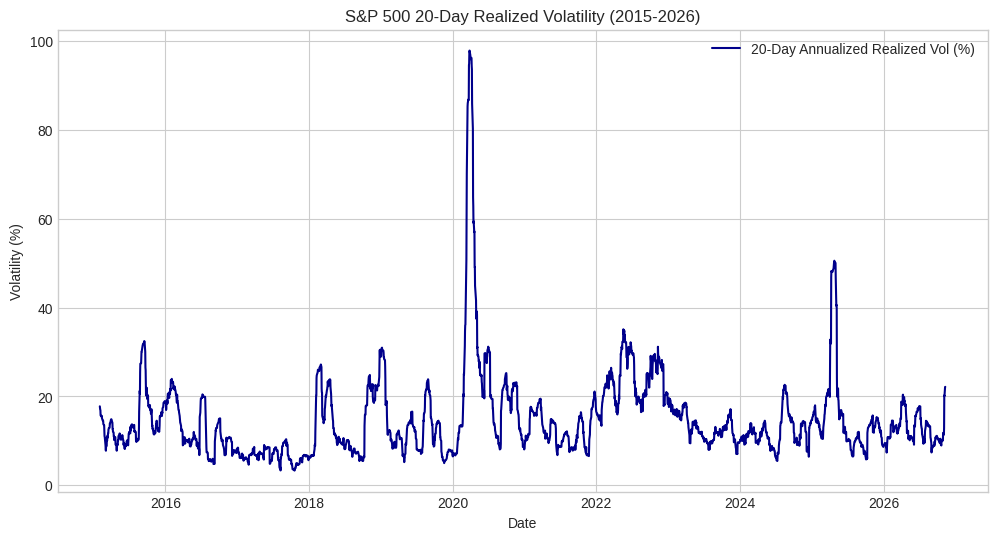

In [14]:
ANN = np.sqrt(252) * 100
data['RV_1d'] = data['Log_Return'].abs() * ANN
data['RV_5d'] = data['Log_Return'].rolling(5).std() * ANN
data['RV_20d'] = data['Log_Return'].rolling(20).std() * ANN
data.dropna(inplace=True)

plt.figure()
plt.plot(data.index, data['RV_20d'], label='20-Day Annualized Realized Vol (%)', color='darkblue')
plt.title(f'S&P 500 20-Day Realized Volatility ({data.index[0].year}-{data.index[-1].year})')
plt.xlabel('Date'); plt.ylabel('Volatility (%)'); plt.legend()
plt.show()

In [15]:
ret = data['Log_Return']
feats = pd.DataFrame(index=data.index)
feats['RV_20d'] = data['RV_20d']
feats['RV_20d_lag20'] = data['RV_20d'].shift(20)
feats['RV_20d_lag40'] = data['RV_20d'].shift(40)
feats['RV_5d'] = data['RV_5d']
feats['RV_60d'] = ret.rolling(60).std() * ANN
feats['Downside_RV_20d'] = np.sqrt((ret.clip(upper=0) ** 2).rolling(20).mean()) * ANN
feats['Return_5d'] = ret.rolling(5).sum() * 100
feats = feats.dropna()

# Target at date t = realized vol over returns t+1 ... t+HORIZON
target = data['RV_20d'].shift(-HORIZON).reindex(feats.index).rename('Target')
df_ml = feats.join(target).dropna()

X = df_ml.drop(columns='Target')
y = df_ml['Target']

# fix --> (target overlap): chronological split with a purge gap, so no training
# target window reaches into the test period.
n_train_end = int(len(df_ml) * TRAIN_FRAC)
X_train, y_train = X.iloc[:n_train_end - GAP], y.iloc[:n_train_end - GAP]
X_test, y_test = X.iloc[n_train_end:], y.iloc[n_train_end:]
print(f"Train: {X_train.index[0].date()} -> {X_train.index[-1].date()} | "
      f"Test: {X_test.index[0].date()} -> {X_test.index[-1].date()}")

Train: 2015-04-28 -> 2024-05-24 | Test: 2024-06-26 -> 2026-10-13


In [16]:
returns_scaled = data['Log_Return'] * 100
garch_specs = {
    'GARCH': dict(vol='Garch', p=1, q=1),
    'GJR-GARCH': dict(vol='Garch', p=1, o=1, q=1),
}

oos = {}
for name, spec in garch_specs.items():
    am = arch_model(returns_scaled, mean='Constant', dist='Normal', **spec)
    res = am.fit(last_obs=X_train.index[-1], disp='off')
    fc = res.forecast(horizon=HORIZON, start=X_test.index[0], reindex=False)
    avg_var = fc.variance.mean(axis=1)                  # %^2 per day
    oos[name] = (np.sqrt(avg_var) * np.sqrt(252)).reindex(y_test.index)

In [17]:
XGB_PARAMS = dict(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
xgb_model = xgb.XGBRegressor(**XGB_PARAMS).fit(X_train, y_train)
oos['XGBoost'] = pd.Series(xgb_model.predict(X_test), index=y_test.index)
oos['Naive (current RV_20d)'] = X_test['RV_20d']


Out-of-sample scores (same window, same target, annualized vol %):
                         RMSE    MAE
Model                               
GJR-GARCH               7.463  4.932
XGBoost                 7.574  4.853
GARCH                   7.890  5.165
Naive (current RV_20d)  9.075  5.954


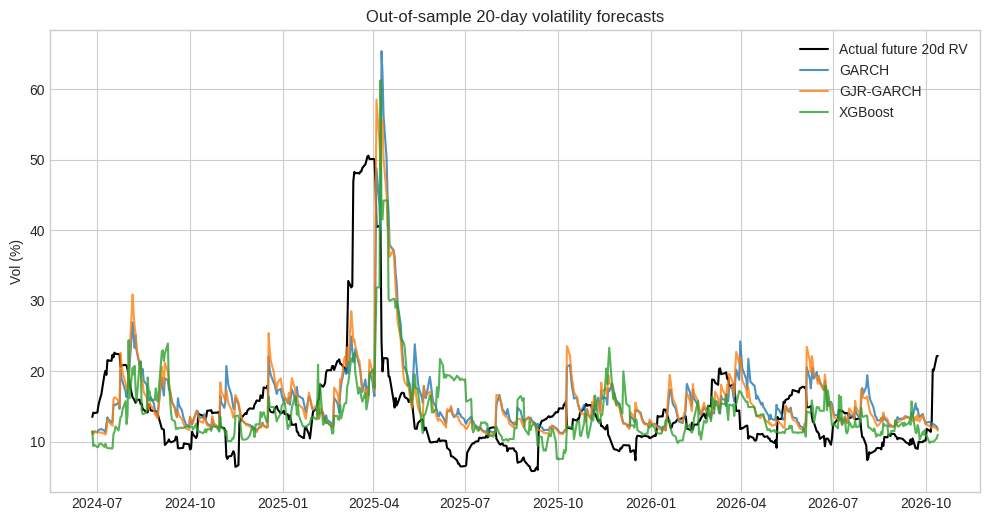


Best model out-of-sample (excluding naive): GJR-GARCH


In [18]:
cmp = pd.concat(oos, axis=1).join(y_test.rename('Actual')).dropna()
rows = []
for name in oos:
    rows.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(cmp['Actual'], cmp[name])),
        'MAE': mean_absolute_error(cmp['Actual'], cmp[name]),
    })
scores = pd.DataFrame(rows).set_index('Model').sort_values('RMSE')
print("\nOut-of-sample scores (same window, same target, annualized vol %):")
print(scores.round(3))

plt.figure()
plt.plot(cmp.index, cmp['Actual'], label='Actual future 20d RV', color='black', lw=1.5)
for name in ['GARCH', 'GJR-GARCH', 'XGBoost']:
    plt.plot(cmp.index, cmp[name], label=name, alpha=0.8)
plt.title('Out-of-sample 20-day volatility forecasts'); plt.ylabel('Vol (%)'); plt.legend()
plt.show()

best_model = scores.drop(index='Naive (current RV_20d)').index[0]
print(f"\nBest model out-of-sample (excluding naive): {best_model}")

In [23]:
naive_rmse = scores.loc['Naive (current RV_20d)', 'RMSE']
improvement = ((naive_rmse - scores['RMSE']) / naive_rmse * 100).round(1)
print("\nRMSE improvement vs naive baseline (%):")
print(improvement.drop('Naive (current RV_20d)'))


RMSE improvement vs naive baseline (%):
Model
GJR-GARCH    17.8
XGBoost      16.5
GARCH        13.1
Name: RMSE, dtype: float64


In [19]:
def bs_price(S, K, T, r, q, sigma, option_type="call"):
    """Black-Scholes European option price with continuous dividend yield."""
    if T <= 0 or sigma <= 0:
        return max(0.0, S - K) if option_type == "call" else max(0.0, K - S)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)


def implied_volatility(market_price, S, K, T, r, q, option_type="call"):
    """Invert Black-Scholes with Brent's method."""
    try:
        f = lambda sig: bs_price(S, K, T, r, q, sig, option_type) - market_price
        return brentq(f, 1e-6, 5.0, xtol=1e-12)
    except ValueError:
        return np.nan

In [20]:
def get_risk_free_rate(default=FALLBACK_RATE):
    """13-week T-bill yield (^IRX) as the risk-free rate."""
    try:
        irx = yf.download("^IRX", period="5d", progress=False, auto_adjust=True)
        close = irx['Close']
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
        return float(close.dropna().iloc[-1]) / 100
    except Exception:
        return default


def get_market_atm_iv(symbol="SPY", target_days=30, r=FALLBACK_RATE, q=DIV_YIELD):
    """ATM implied vol from the live option chain (call/put mid prices averaged)."""
    try:
        tk = yf.Ticker(symbol)
        spot = float(tk.history(period="5d")['Close'].dropna().iloc[-1])
        today = pd.Timestamp.today().normalize()
        expiries = pd.to_datetime(tk.options)
        days = np.array((expiries - today).days)
        expiry = expiries[int(np.argmin(np.abs(days - target_days)))]
        T = (expiry - today).days / 365.0

        chain = tk.option_chain(expiry.strftime('%Y-%m-%d'))
        strikes = chain.calls['strike'].values
        K = float(strikes[int(np.argmin(np.abs(strikes - spot)))])

        def mid(df):
            row = df[df['strike'] == K].iloc[0]
            if row['bid'] > 0 and row['ask'] > 0:
                return (row['bid'] + row['ask']) / 2
            return row['lastPrice']

        c, p = mid(chain.calls), mid(chain.puts)
        iv = np.nanmean([implied_volatility(c, spot, K, T, r, q, "call"),
                         implied_volatility(p, spot, K, T, r, q, "put")])
        if not np.isfinite(iv):
            raise ValueError("Implied vol did not converge")
        return dict(iv=float(iv), spot=spot, strike=K, T=T, expiry=expiry,
                    source=f"{symbol} option chain")
    except Exception as e:
        print(f"[warning] Could not fetch live option chain ({e}).")
        return None


r_rate = get_risk_free_rate()
mkt = get_market_atm_iv(r=r_rate)

if mkt is None:
    spot = float(data['Close'].iloc[-1])
    mkt = dict(iv=MANUAL_IV, spot=spot, strike=round(spot / 5) * 5, T=30 / 365.0,
               expiry=None, source="MANUAL FALLBACK (not a real quote)")

S_0, K_strike, T_exp, market_iv = mkt['spot'], mkt['strike'], mkt['T'], mkt['iv']
print(f"\nMarket inputs [{mkt['source']}]")
print(f"  Spot {S_0:.2f} | Strike {K_strike:.2f} | T {T_exp*365:.0f} days | "
      f"r {r_rate*100:.2f}% | q {DIV_YIELD*100:.2f}% | ATM IV {market_iv*100:.2f}%")


Market inputs [SPY option chain]
  Spot 748.42 | Strike 748.00 | T 31 days | r 4.12% | q 1.30% | ATM IV 16.27%


In [21]:
h_option = max(1, int(round(T_exp * 252)))

live = {}
for name, spec in garch_specs.items():
    res_full = arch_model(returns_scaled, mean='Constant', dist='Normal', **spec).fit(disp='off')
    fc = res_full.forecast(horizon=h_option)
    live[name] = float(np.sqrt(fc.variance.iloc[-1].mean() * 252)) / 100   # decimal

# XGBoost: retrain on all labelled data, predict from the latest feature row
# (the latest rows have no target yet, so they are not in X/y).
xgb_live = xgb.XGBRegressor(**XGB_PARAMS).fit(X, y)
live['XGBoost'] = float(xgb_live.predict(feats.iloc[[-1]])[0]) / 100       # decimal

In [22]:
print(f"\n{'Model':<12}{'Fcst vol':>10}{'Edge vs IV':>12}{'Straddle $':>12}")
mkt_straddle = (bs_price(S_0, K_strike, T_exp, r_rate, DIV_YIELD, market_iv, "call")
                + bs_price(S_0, K_strike, T_exp, r_rate, DIV_YIELD, market_iv, "put"))
for name, v in live.items():
    st = (bs_price(S_0, K_strike, T_exp, r_rate, DIV_YIELD, v, "call")
          + bs_price(S_0, K_strike, T_exp, r_rate, DIV_YIELD, v, "put"))
    print(f"{name:<12}{v*100:>9.2f}%{(v-market_iv)*100:>+11.2f}%{st:>12.2f}")
print(f"{'Market':<12}{market_iv*100:>9.2f}%{'':>12}{mkt_straddle:>12.2f}")

chosen_vol = live[best_model]
edge = chosen_vol - market_iv
print(f"\nSignal model: {best_model} | forecast {chosen_vol*100:.2f}% vs IV {market_iv*100:.2f}% "
      f"-> edge {edge*100:+.2f} pts (threshold {MIN_EDGE*100:.0f} pts)")

if edge > MIN_EDGE:
    print("Signal: Options appear UNDERPRICED. Strategy: Buy Straddle / Long Vega.")
elif edge < -MIN_EDGE:
    print("Signal: Options appear OVERPRICED. Strategy: Sell Straddle / Short Vega.")
else:
    print("Signal: Fairly valued (within threshold). No trade.")

print("\nNote: implied vol usually exceeds subsequent realized vol on average "
      "(variance risk premium), and this ignores costs, hedging and risk limits. "
      "This is a research demo, not trading advice.")



Model         Fcst vol  Edge vs IV  Straddle $
GARCH           25.45%      +9.18%       44.21
GJR-GARCH       27.08%     +10.81%       47.03
XGBoost         15.61%      -0.66%       27.16
Market          16.27%                   28.30

Signal model: GJR-GARCH | forecast 27.08% vs IV 16.27% -> edge +10.81 pts (threshold 2 pts)
Signal: Options appear UNDERPRICED. Strategy: Buy Straddle / Long Vega.

Note: implied vol usually exceeds subsequent realized vol on average (variance risk premium), and this ignores costs, hedging and risk limits. This is a research demo, not trading advice.
